# CSC 425 Milestone 3: Working System & Preliminary Evaluation

**Project:** Sentiment Analysis of IMDb Movie Reviews

Milestone 2 showed that TF-IDF models score ~86-88% on real reviews but treat "not" as a plain negative word. This milestone asks:
1. How much does **tuning** help?
2. Does explicit **negation marking** (`not good` -> `not not_good`) fix the negation problem?
3. Does **more training data** fix it?
4. How well does the chosen model do on the **official 25,000-review test set**?

In [1]:
import sys
sys.path.insert(0, "../src")
import pandas as pd
from IPython.display import Image, display
from negation import mark_negation
from data_prep import load_split, clean_text
from negation import expand_contractions

R = "../results/m3/"
pd.set_option("display.max_colwidth", 100)

## 1. Negation marking

Following Das & Chen (2001) and Pang et al. (2002), every word after a negation word gets a `not_` prefix until the next punctuation mark or a contrast word like "but".

In [2]:
for s in ["the film was not boring at all.",
          "i didn't like the ending, but the music was great.",
          "it was not a great movie."]:
    print(f"{s}\n  -> {mark_negation(s)}\n")

the film was not boring at all.
  -> the film was not not_boring not_at not_all .

i didn't like the ending, but the music was great.
  -> i did not not_like not_the not_ending , but the music was great .

it was not a great movie.
  -> it was not not_a not_great not_movie .



## 2. Tuning (validation set, 3,200 training reviews)

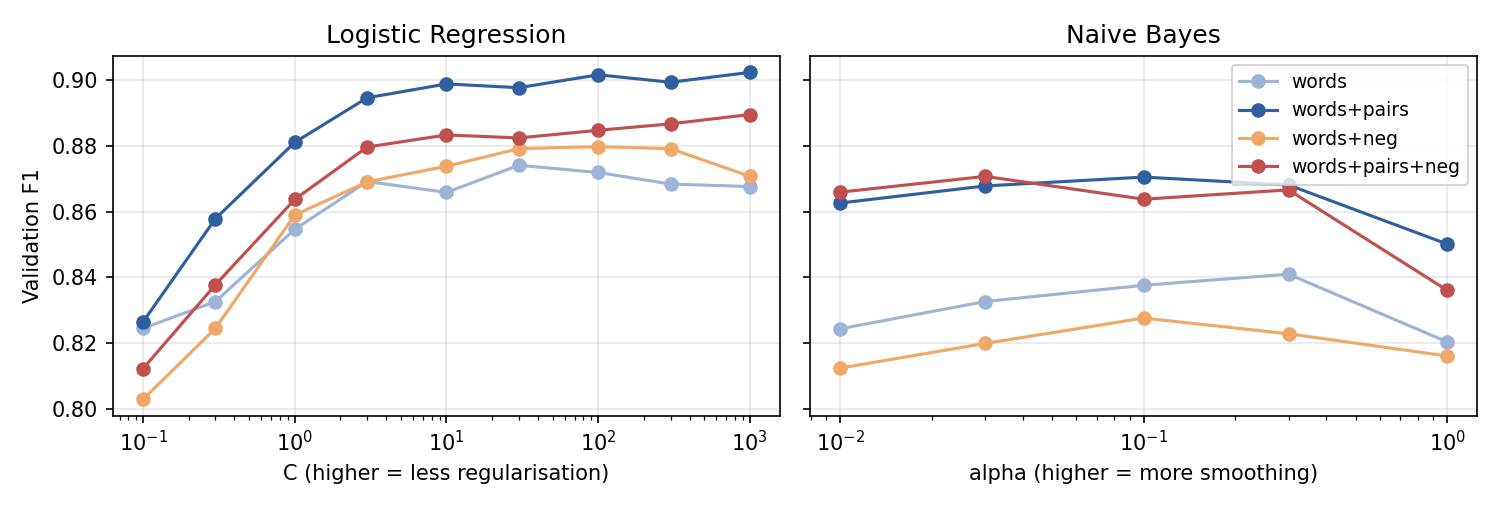

model    LogReg                                       NaiveBayes            \
features  words words+neg words+pairs words+pairs+neg      words words+neg   
strength                                                                     
0.01        NaN       NaN         NaN             NaN      0.824     0.812   
0.03        NaN       NaN         NaN             NaN      0.833     0.820   
0.10      0.825     0.803       0.826           0.812      0.838     0.828   
0.30      0.833     0.825       0.858           0.838      0.841     0.823   
1.00      0.855     0.859       0.881           0.864      0.820     0.816   
3.00      0.869     0.869       0.894           0.880        NaN       NaN   
10.00     0.866     0.874       0.899           0.883        NaN       NaN   
30.00     0.874     0.879       0.898           0.882        NaN       NaN   
100.00    0.872     0.880       0.902           0.885        NaN       NaN   
300.00    0.868     0.879       0.899           0.887        NaN       NaN   
1000.00   0.868     0.871       0.902           0.890        NaN       NaN   

model                                 
features words+pairs words+pairs+neg  
strength                              
0.01           0.863           0.866  
0.03           0.868           0.871  
0.10           0.870           0.864  
0.30           0.868           0.867  
1.00           0.850           0.836  
3.00             NaN             NaN  
10.00            NaN             NaN  
30.00            NaN             NaN  
100.00           NaN             NaN  
300.00           NaN             NaN  
1000.00          NaN             NaN

In [3]:
display(Image(R + "figures/tuning.png"))
pd.read_csv(R + "tuning.csv").pivot_table(index="strength", columns=["model", "features"], values="f1").round(3)

## 3. Negation handling at the tuned settings

In [4]:
cols = ["model", "features", "strength", "n_features", "accuracy", "precision", "recall", "f1",
        "neg_sentences", "neg_pairs", "mixed", "sarcasm"]
pd.read_csv(R + "comparison.csv")[cols]

,model,features,strength,n_features,accuracy,precision,recall,f1,neg_sentences,neg_pairs,mixed,sarcasm
0,LogReg,words,30.00,17291,0.875,0.881,0.868,0.874,13,3,8,5
1,LogReg,words+pairs,1000.00,82919,0.902,0.905,0.900,0.902,14,4,8,7
2,LogReg,words+neg,100.00,20207,0.880,0.882,0.878,0.880,15,5,7,6
3,LogReg,words+pairs+neg,1000.00,86648,0.891,0.904,0.875,0.889,16,6,8,7
4,NaiveBayes,words,0.30,17291,0.849,0.886,0.800,0.841,12,2,9,9
5,NaiveBayes,words+pairs,0.10,82919,0.875,0.903,0.840,0.870,13,3,9,9
6,NaiveBayes,words+neg,0.10,20207,0.835,0.866,0.792,0.828,15,5,9,9
7,NaiveBayes,words+pairs+neg,0.03,86648,0.874,0.892,0.850,0.871,13,3,9,8


### Is the difference real? Five more random splits

800 validation reviews is a small sample (a 95% interval for accuracy is roughly ±2 points), so the Logistic Regression comparison is repeated on five other random 3,200/800 splits.

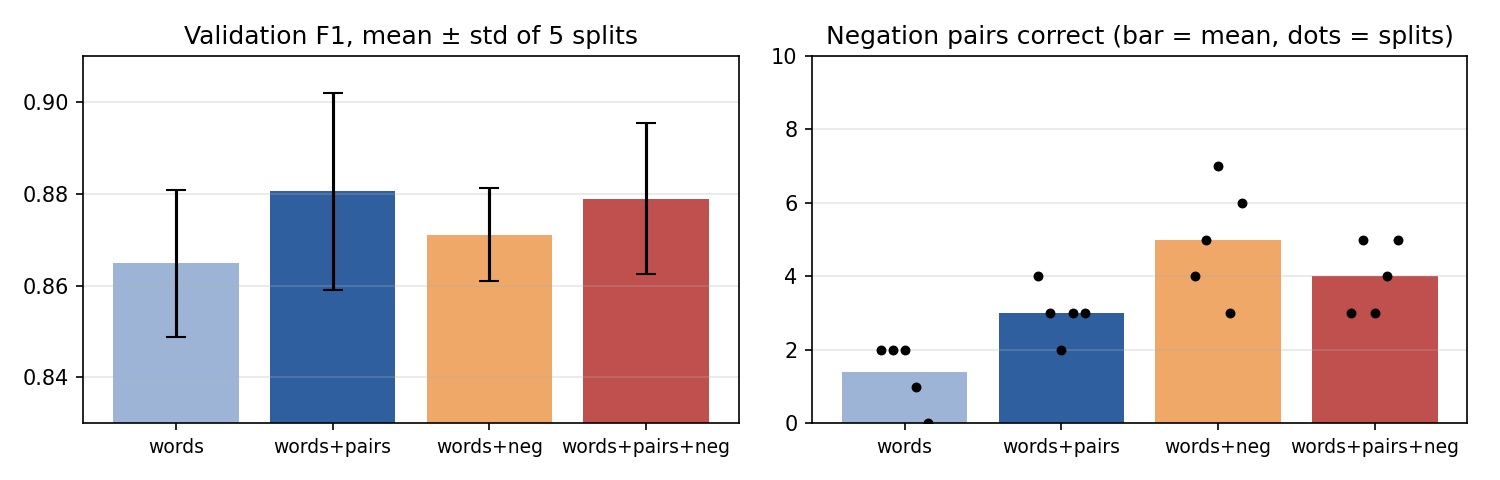

,features,f1_mean,f1_std,f1_min,f1_max,neg_pairs_mean,neg_pairs_min,neg_pairs_max
0,words,0.865,0.016,0.846,0.885,1.4,0,2
1,words+pairs,0.881,0.021,0.860,0.912,3.0,2,4
2,words+neg,0.871,0.010,0.864,0.889,5.0,3,7
3,words+pairs+neg,0.879,0.016,0.867,0.906,4.0,3,5


In [5]:
display(Image(R + "figures/stability.png"))
pd.read_csv(R + "stability_summary.csv")

In [6]:
runs = pd.read_csv(R + "stability_runs.csv")
runs.pivot(index="seed", columns="features", values="neg_pairs")

features,words,words+neg,words+pairs,words+pairs+neg
seed,,,,
1,2,4,4,3
2,2,5,3,5
3,2,7,2,3
4,1,3,3,4
5,0,6,3,5


## 4. Negation scope (how many words to mark)

In [7]:
pd.read_csv(R + "negation_scope.csv")

,window,accuracy,precision,recall,f1,neg_sentences,neg_pairs,mixed,sarcasm
0,1,0.901,0.915,0.885,0.900,14,4,8,6
1,2,0.901,0.902,0.900,0.901,15,5,9,7
2,3,0.895,0.905,0.882,0.894,14,4,9,6
3,to punctuation,0.891,0.904,0.875,0.889,16,6,8,7


## 5. Learning curve: does more data fix negation?

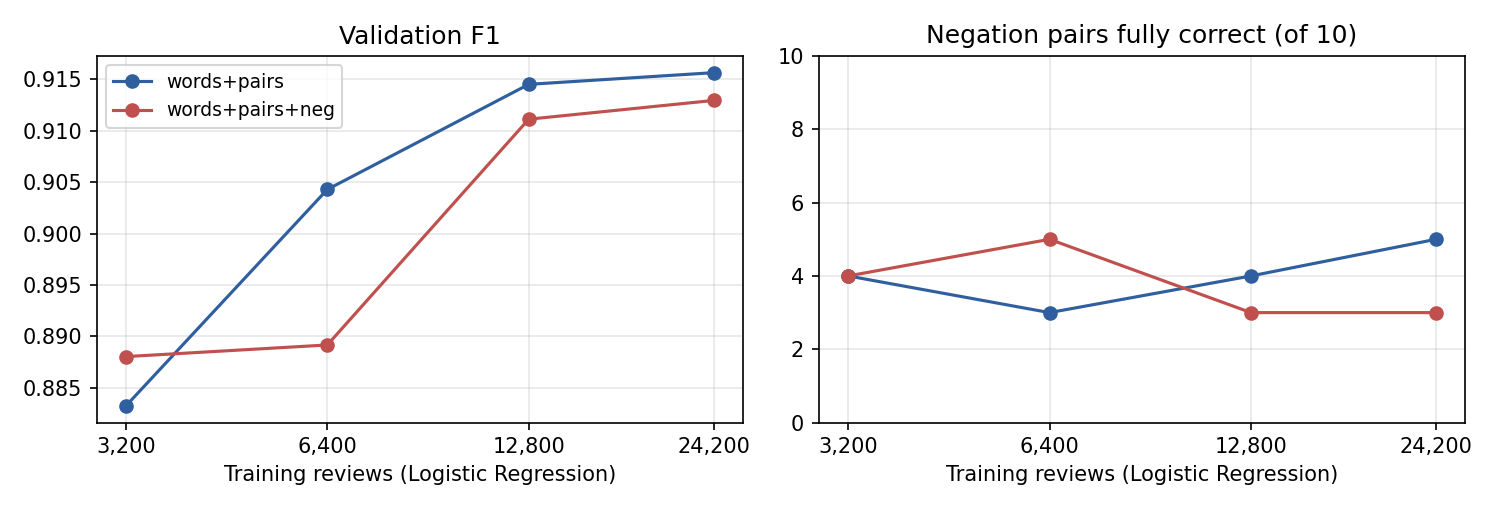

,train_size,features,accuracy,f1,neg_pairs,mixed,sarcasm
0,3200,words+pairs,0.885,0.883,4,8,4
1,3200,words+pairs+neg,0.890,0.888,4,6,4
2,6400,words+pairs,0.905,0.904,3,9,6
3,6400,words+pairs+neg,0.891,0.889,5,8,6
4,12800,words+pairs,0.914,0.914,4,9,7
5,12800,words+pairs+neg,0.910,0.911,3,9,5
6,24200,words+pairs,0.915,0.916,5,9,7
7,24200,words+pairs+neg,0.912,0.913,3,9,6


In [8]:
display(Image(R + "figures/learning_curve.png"))
pd.read_csv(R + "learning_curve.csv")[["train_size", "features", "accuracy", "f1", "neg_pairs", "mixed", "sarcasm"]]

### Why more data does not help: how IMDb reviewers actually use "not"

For each phrase: how many of the 25,000 training reviews contain it, and what share of those reviews are positive. The model learns these review-level associations.

In [9]:
train = load_split("train")
train["t"] = train["text"].map(clean_text).map(expand_contractions)
rows = []
for ph in ["not bad", "not boring", "not great", "not good", "not funny", "not worth", "funny", "good", "bad"]:
    m = train["t"].str.contains(rf"\b{ph}\b")
    rows.append({"phrase": ph, "reviews": int(m.sum()), "share positive": round(train.loc[m, "label"].mean(), 2)})
pd.DataFrame(rows)

,phrase,reviews,share positive
0,not bad,274,0.33
1,not boring,19,0.53
2,not great,128,0.52
3,not good,184,0.24
4,not funny,298,0.07
5,not worth,270,0.09
6,funny,3141,0.48
7,good,9641,0.50
8,bad,5904,0.25


## 6. Official test set (used once)

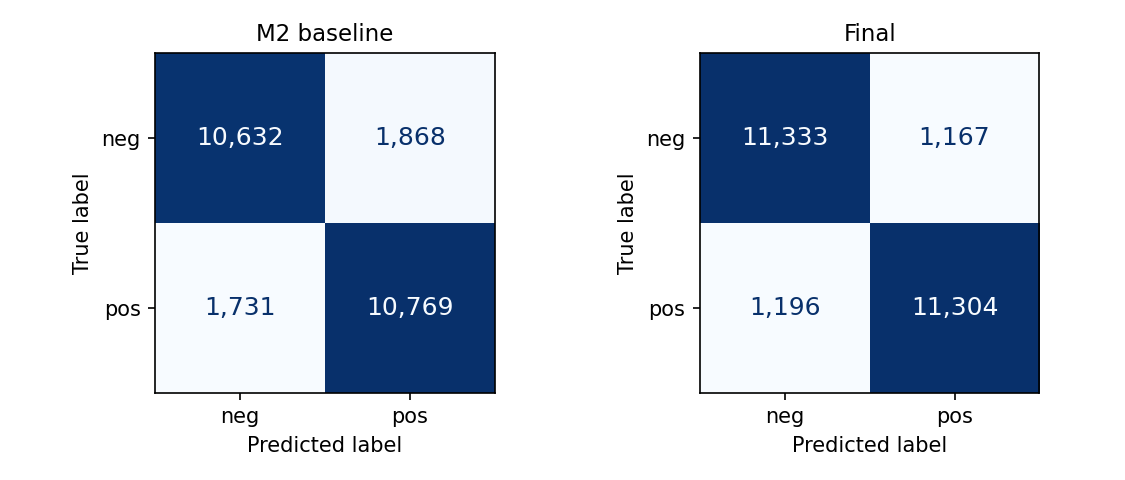

,model,train_reviews,accuracy,precision,recall,f1,neg_sentences,neg_pairs,mixed,sarcasm
0,"M2 baseline (LogReg, words+pairs, 3,200 reviews)",3200,0.856,0.852,0.862,0.857,13,3,8,4
1,"Final (LogReg, words+pairs, 25,000 reviews)",25000,0.905,0.906,0.904,0.905,14,4,9,7


In [10]:
display(Image(R + "figures/test_confusion.png"))
pd.read_csv(R + "test_results.csv")

## 7. Error analysis

In [11]:
p = pd.read_csv(R + "predictions_negation.csv")
p[["pair_id", "text", "label", "baseline", "final"]]

,pair_id,text,label,baseline,final
0,1,The movie was enjoyable.,positive,negative (0.53),positive (1.00)
1,1,The movie was not enjoyable.,negative,negative (0.60),positive (0.81)
2,2,I would recommend this movie.,positive,positive (0.55),positive (1.00)
3,2,I would not recommend this movie.,negative,negative (0.57),negative (1.00)
4,3,The acting was good.,positive,negative (0.64),positive (0.96)
5,3,The acting was not good.,negative,negative (0.76),negative (1.00)
6,4,This film is worth watching.,positive,positive (0.65),positive (1.00)
7,4,This film is not worth watching.,negative,positive (0.50),negative (1.00)
8,5,I liked the ending.,positive,positive (0.62),positive (1.00)
9,5,I did not like the ending.,negative,negative (0.51),negative (0.96)


In [12]:
p = pd.read_csv(R + "predictions_mixed_sarcasm.csv")
p[["category", "text", "label", "baseline", "final"]]

,category,text,label,baseline,final
0,mixed,"The movie was good, but the ending ruined it.",negative,negative (0.59),negative (0.99)
1,mixed,"I expected to hate it, but I loved it.",positive,positive (0.65),positive (1.00)
2,mixed,"The acting was weak, but the story kept me hooked until the end.",positive,negative (0.57),negative (0.81)
3,mixed,Beautiful visuals cannot save a boring and predictable script.,negative,negative (0.68),negative (1.00)
4,mixed,"It starts slow, but the last hour is brilliant.",positive,positive (0.57),positive (0.90)
5,mixed,"Great cast, wasted on a lazy plot.",negative,positive (0.55),negative (0.79)
6,mixed,"Not perfect, but I enjoyed every minute.",positive,positive (0.70),positive (1.00)
7,mixed,"The first half was fun, then it fell apart completely.",negative,negative (0.62),negative (0.99)
8,mixed,"Some scenes drag, but overall it is a wonderful film.",positive,positive (0.73),positive (1.00)
9,mixed,A promising idea with awful execution.,negative,negative (0.62),negative (1.00)


The test reviews the final model got wrong with the highest confidence:

In [13]:
pd.read_csv(R + "test_confident_errors.csv")

,review_id,true,pred,conf,excerpt
0,12061,negative,positive,1.0,This movie was pure genius. John Waters is brilliant. It is hilarious and I am not sick of it ev...
1,6245,negative,positive,1.0,Mickey Rourke hunts Diane Lane in Elmore Leonard's Killshot It is not like Mickey Rourke ever re...
2,4118,negative,positive,1.0,This is definitely one of the best Kung fu movies in the history of Cinema. The screenplay is re...
3,7109,negative,positive,1.0,"This has to be one of, if not THE greatest Mob/Crime films of all time. Every thing about this m..."
4,20621,positive,negative,1.0,"This was Laurel and Hardy's last silent film for Roach Studios. However, since the public had a ..."
5,3757,negative,positive,1.0,"I went to see this 3 nights ago here in Cork, Ireland. It was the world premiere of it, in the t..."
6,5331,negative,positive,1.0,I enjoyed the beautiful scenery in this movie the first time I saw it when I was 9 . Dunderklump...
7,3553,negative,positive,1.0,"This film has the language, the style and the attitude down ... plus greats rides from Occy (a w..."
8,776,negative,positive,1.0,"In all honesty, I haven't seen this film for many years, but the few times I have tend to make p..."
9,9827,negative,positive,1.0,"Going into the movie with the right expectations, I somewhat liked this movie. Like most reviewe..."
